In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

print("All tools are ready!")


In [2]:
from pathlib import Path

data_folder = Path.home() / "Downloads" / "archive" / "kaggle" / "data"

print("Folder found:", data_folder.exists())

if data_folder.exists():
    for folder in data_folder.iterdir():
        print(folder.name)
        

Folder found: True
Class_0
Class_1
sample


In [3]:
metadata_folder = data_folder.parent / "metadata"

for file in metadata_folder.rglob("*"):
    if file.is_file():
        print(file.relative_to(metadata_folder))
        

dataset_metadata.xml
dataset_readme.md
license.html


In [4]:
readme_file = metadata_folder / "dataset_readme.md"

print(readme_file.read_text(encoding="utf-8"))


# How metadata versions work

Collections in CSIRO's [Data Access Portal](https://data.csiro.au), DAP, are
versioned. A new version may have new or modified files from its previous
version, or it may be a metadata only update. When a collection has had only its
metadata updated, all versions of the metadata and licences are stored with the
original, unchanged files.

Files with a name like `dublin-core-v1.xml` will contain a minimal description
of the DAP collection. You may be able to import this into reference management
software that supports this schema. The files will contain a URL that you can
follow to find the full description of the DAP collection.

It's possible that the changes to the DAP collection metadata between versions
do not involve any of the metadata fields contained in the Dublin Core XML
files, in which case the metadata files will have very similar content. If the
citation details of the DAP collection have changed, or if a different licence
has been specified, t

In [5]:
import xml.etree.ElementTree as ET

metadata_file = metadata_folder / "dataset_metadata.xml"
root = ET.parse(metadata_file).getroot()

for element in root.iter():
    tag = element.tag.split("}")[-1]

    if tag.lower() in ["title", "description", "subject"]:
        text = " ".join(element.itertext()).strip()
        print(tag, ":", text)
        print()
        

title : CSIRO Sentinel-1 SAR image dataset of oil- and non-oil features for machine learning ( Deep Learning )

subject : Computer Software not elsewhere classified

subject : Environmental Management

description : What this collection is:
A curated, binary-classified image dataset of grayscale (1 band) 400 x 400-pixel size, or image chips, in a JPEG format extracted from processed Sentinel-1 Synthetic Aperture Radar (SAR) satellite scenes acquired over various regions of the world, and featuring clear open ocean chips, look-alikes (wind or biogenic features) and oil slick chips.

This binary dataset contains chips  labelled as:
- &quot;0&quot; for chips not containing any oil features (look-alikes or clean seas)  
- &quot;1&quot; for those containing oil features. 

This binary dataset is imbalanced, and biased towards &quot;0&quot; labelled chips (i.e.,  no oil features), which correspond to 66% of the dataset.
Chips containing oil features, labelled &quot;1&quot;, correspond to 34%

In [6]:
import xml.etree.ElementTree as ET

metadata_file = metadata_folder / "dataset_metadata.xml"
root = ET.parse(metadata_file).getroot()

for element in root.iter():
    tag = element.tag.split("}")[-1]

    if tag.lower() in ["title", "description", "subject"]:
        print(tag, ":", " ".join(element.itertext()).strip())
        print()

title : CSIRO Sentinel-1 SAR image dataset of oil- and non-oil features for machine learning ( Deep Learning )

subject : Computer Software not elsewhere classified

subject : Environmental Management

description : What this collection is:
A curated, binary-classified image dataset of grayscale (1 band) 400 x 400-pixel size, or image chips, in a JPEG format extracted from processed Sentinel-1 Synthetic Aperture Radar (SAR) satellite scenes acquired over various regions of the world, and featuring clear open ocean chips, look-alikes (wind or biogenic features) and oil slick chips.

This binary dataset contains chips  labelled as:
- &quot;0&quot; for chips not containing any oil features (look-alikes or clean seas)  
- &quot;1&quot; for those containing oil features. 

This binary dataset is imbalanced, and biased towards &quot;0&quot; labelled chips (i.e.,  no oil features), which correspond to 66% of the dataset.
Chips containing oil features, labelled &quot;1&quot;, correspond to 34%

In [7]:
import pandas as pd

image_types = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

class_0_images = sorted(
    file for file in (data_folder / "Class_0").rglob("*")
    if file.is_file() and file.suffix.lower() in image_types
)

class_1_images = sorted(
    file for file in (data_folder / "Class_1").rglob("*")
    if file.is_file() and file.suffix.lower() in image_types
)

class_counts = pd.DataFrame({
    "Class": ["Non-oil-spill", "Oil-spill"],
    "Number of images": [len(class_0_images), len(class_1_images)]
})

class_counts["Percentage"] = (
    class_counts["Number of images"]
    / class_counts["Number of images"].sum() * 100
).round(2)

display(class_counts)

,Class,Number of images,Percentage
0,Non-oil-spill,3695,66.72
1,Oil-spill,1843,33.28


In [8]:
from collections import Counter

for name in ["Class_0", "Class_1", "sample"]:
    folder = data_folder / name

    file_types = Counter(
        file.suffix.lower()
        for file in folder.rglob("*")
        if file.is_file()
    )

    print(name, ":", dict(file_types))

Class_0 : {'.jpg': 3695}
Class_1 : {'.jpg': 1843}
sample : {'.jpg': 10}


Matplotlib is building the font cache; this may take a moment.


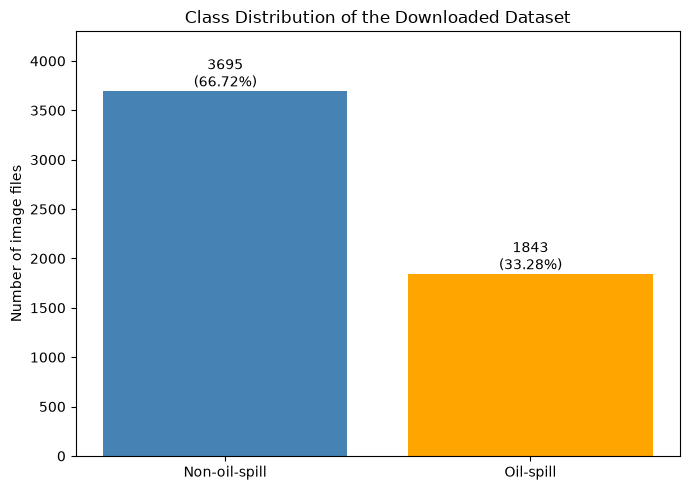

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    class_counts["Class"],
    class_counts["Number of images"],
    color=["steelblue", "orange"]
)

for bar, percentage in zip(bars, class_counts["Percentage"]):
    count = int(bar.get_height())

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{count}\n({percentage}%)",
        ha="center",
        va="bottom"
    )

plt.title("Class Distribution of the Downloaded Dataset")
plt.ylabel("Number of image files")
plt.ylim(0, 4300)
plt.tight_layout()
plt.show()

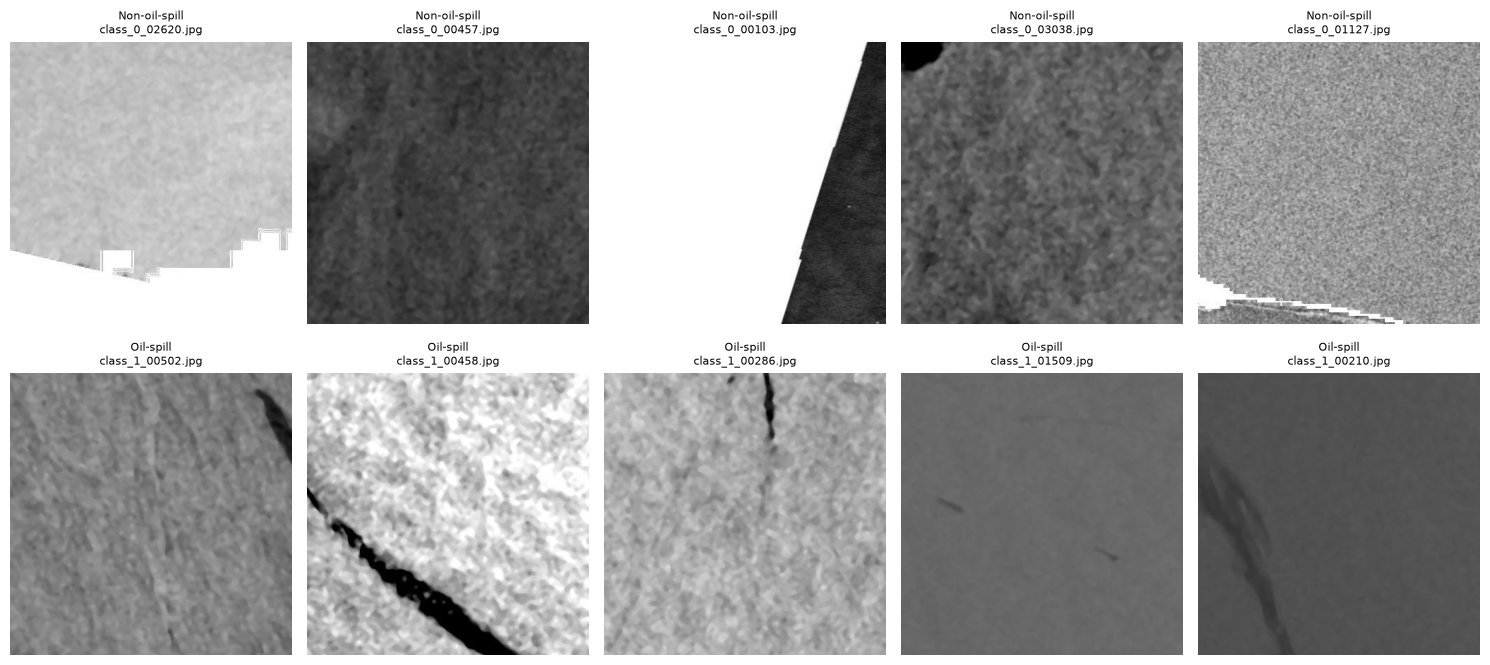

In [10]:
import random
import cv2
import matplotlib.pyplot as plt

rng = random.Random(42)

image_groups = [
    ("Non-oil-spill", class_0_images),
    ("Oil-spill", class_1_images)
]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, (label, files) in enumerate(image_groups):
    selected = rng.sample(files, 5)

    for column, file in enumerate(selected):
        image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
        ax = axes[row, column]

        if image is None:
            ax.text(0.5, 0.5, "Could not read image", ha="center")
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)

        ax.set_title(f"{label}\n{file.name}", fontsize=8)
        ax.axis("off")

plt.tight_layout()

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

plt.savefig(output_folder / "random_image_comparison.png", dpi=150)
plt.show()

In [11]:
import numpy as np
import pandas as pd
import cv2

results = []
unreadable = []

for label, files in image_groups:
    for file in files:
        image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)

        if image is None:
            unreadable.append(str(file))
            continue

        results.append({
            "filename": file.name,
            "path": str(file),
            "class": label,
            "height": image.shape[0],
            "width": image.shape[1],
            "mean_intensity": np.mean(image),
            "std_intensity": np.std(image),
            "white_pixel_percent": np.mean(image == 255) * 100
        })

image_stats = pd.DataFrame(results)

image_stats.to_csv(
    output_folder / "image_statistics.csv", index=False
)

pd.DataFrame({"path": unreadable}).to_csv(
    output_folder / "unreadable_images.csv", index=False
)

print("Images measured:", len(image_stats))
print("Unreadable images:", len(unreadable))

display(image_stats.head())

display(
    image_stats.groupby("class")[
        ["mean_intensity", "std_intensity"]
    ].describe().round(2)
)

Images measured: 5538
Unreadable images: 0


,filename,path,class,height,width,mean_intensity,std_intensity,white_pixel_percent
0,class_0_00001.jpg,C:\Users\svetl\Downloads\archive\kaggle\data\C...,Non-oil-spill,400,400,113.674981,31.910500,0.000000
1,class_0_00002.jpg,C:\Users\svetl\Downloads\archive\kaggle\data\C...,Non-oil-spill,400,400,159.215550,41.057468,0.000625
2,class_0_00003.jpg,C:\Users\svetl\Downloads\archive\kaggle\data\C...,Non-oil-spill,400,400,181.227625,16.467608,0.000000
3,class_0_00004.jpg,C:\Users\svetl\Downloads\archive\kaggle\data\C...,Non-oil-spill,400,400,114.153369,2.853721,0.000000
4,class_0_00005.jpg,C:\Users\svetl\Downloads\archive\kaggle\data\C...,Non-oil-spill,400,400,95.933169,6.958901,0.000000


mean_intensity                                                \
                       count    mean    std    min     25%     50%     75%   
class                                                                        
Non-oil-spill         3695.0  137.71  49.59   3.93  100.15  138.18  174.07   
Oil-spill             1843.0  122.12  39.31  34.70   91.48  113.99  147.81   

                      std_intensity                                           \
                  max         count   mean    std   min    25%    50%    75%   
class                                                                          
Non-oil-spill  255.00        3695.0  28.09  22.62  0.00  12.57  21.01  38.36   
Oil-spill      236.54        1843.0  14.46  13.39  1.91   4.62  10.40  19.62   

                       
                  max  
class                  
Non-oil-spill  126.47  
Oil-spill       98.79

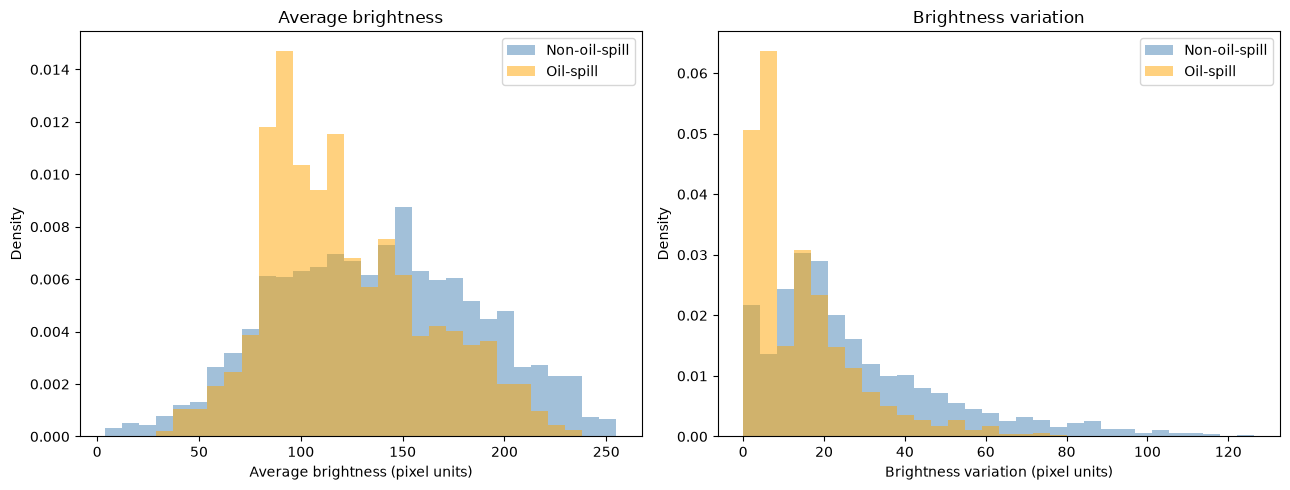

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

features = [
    ("mean_intensity", "Average brightness"),
    ("std_intensity", "Brightness variation")
]

for ax, (column, title) in zip(axes, features):
    bins = np.linspace(
        image_stats[column].min(),
        image_stats[column].max(),
        31
    )

    for label, color in [
        ("Non-oil-spill", "steelblue"),
        ("Oil-spill", "orange")
    ]:
        values = image_stats.loc[
            image_stats["class"] == label, column
        ]

        ax.hist(
            values,
            bins=bins,
            density=True,
            alpha=0.5,
            color=color,
            label=label
        )

    ax.set_title(title)
    ax.set_xlabel(title + " (pixel units)")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.savefig(output_folder / "intensity_distributions.png", dpi=150)
plt.show()

### Image Intensity — Findings

The brightness histogram shows that oil-spill images are more
concentrated at lower mean intensities, while non-oil-spill images
have a broader distribution extending towards brighter values.

The average image brightness was 122.12 for the oil-spill class
and 137.71 for the non-oil-spill class.

Oil-spill images also generally showed lower within-image brightness
variation. Their average pixel standard deviation was 14.46,
compared with 28.09 for non-oil-spill images.

However, both distributions overlap substantially. Therefore,
brightness and global contrast provide useful exploratory clues,
but neither gives a clear rule for distinguishing the classes.

These measurements describe the stored grayscale JPEG values,
not calibrated radar backscatter. Bright areas, image borders
and preprocessing may influence the results. Global standard
deviation does not describe the shape or location of dark features.

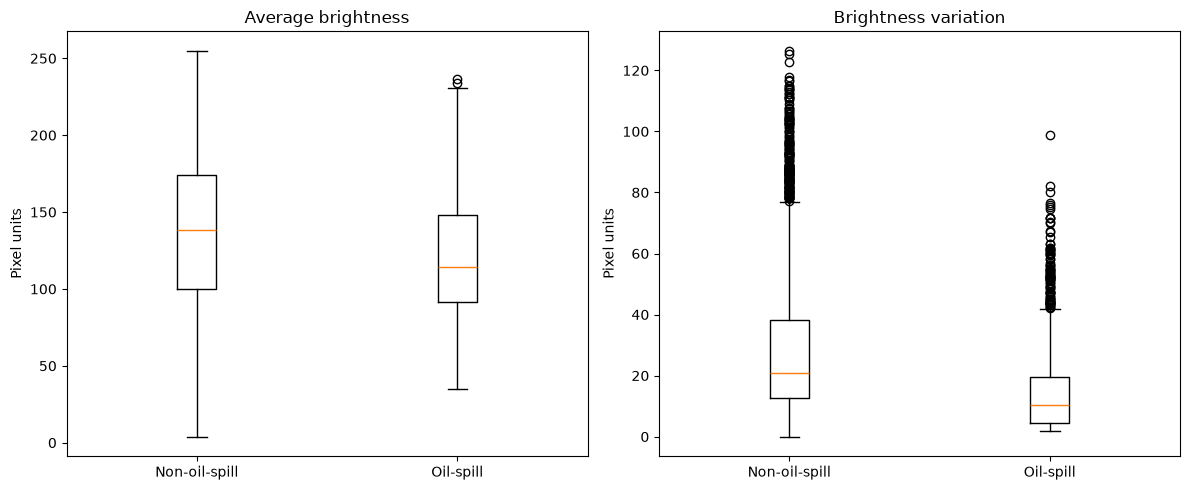

In [13]:
labels = ["Non-oil-spill", "Oil-spill"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column, title in zip(
    axes,
    ["mean_intensity", "std_intensity"],
    ["Average brightness", "Brightness variation"]
):
    values = [
        image_stats.loc[image_stats["class"] == label, column]
        for label in labels
    ]

    ax.boxplot(values, tick_labels=labels)
    ax.set_title(title)
    ax.set_ylabel("Pixel units")

plt.tight_layout()
plt.savefig(output_folder / "intensity_boxplots.png", dpi=150)
plt.show()

### Box Plots and Potential Outliers

The median brightness was 138.18 for non-oil-spill images and
113.99 for oil-spill images. The overlapping boxes show that
many images from both classes have similar brightness.

Non-oil-spill images also have a higher median pixel standard
deviation, indicating greater within-image brightness variation.

Both classes contain unusually high standard-deviation values.
These images may contain strongly contrasting bright and dark
regions, but visual inspection is needed to investigate the cause.

Only a few oil-spill images are flagged for unusually high mean
brightness. No mean-brightness outliers are visible for the
non-oil-spill class under the 1.5 × IQR rule. This does not mean
that the class contains no visually unusual images.

Outliers were identified separately within each class and retained
for investigation rather than automatically removed.

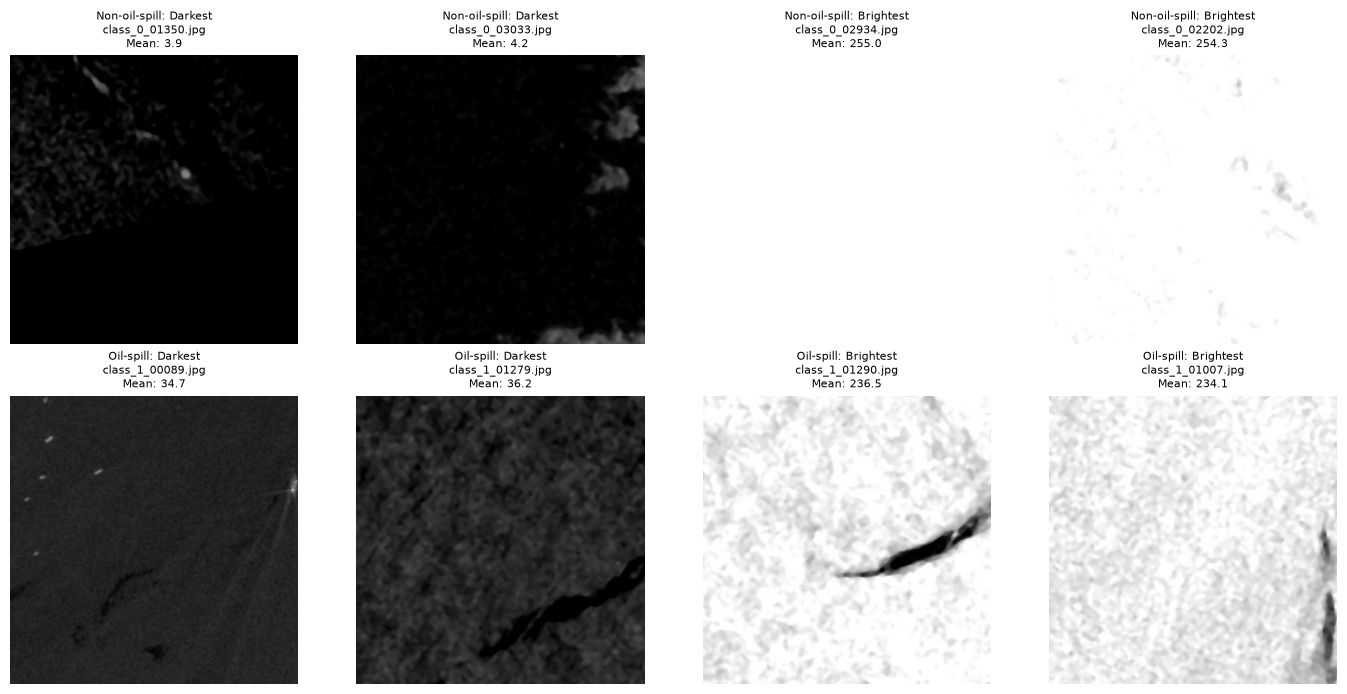

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
extreme_groups = []

for row, label in enumerate(labels):
    group = image_stats[image_stats["class"] == label]

    darkest = group.nsmallest(2, "mean_intensity")
    brightest = group.nlargest(2, "mean_intensity")

    extremes = pd.concat([darkest, brightest])
    extreme_groups.append(extremes)

    for column, (_, record) in enumerate(extremes.iterrows()):
        image = cv2.imread(record["path"], cv2.IMREAD_GRAYSCALE)
        ax = axes[row, column]

        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

        category = "Darkest" if column < 2 else "Brightest"

        ax.set_title(
            f"{label}: {category}\n"
            f"{record['filename']}\n"
            f"Mean: {record['mean_intensity']:.1f}",
            fontsize=8
        )
        ax.axis("off")

plt.tight_layout()
plt.savefig(output_folder / "intensity_extremes.png", dpi=150)
plt.show()

extreme_images = pd.concat(extreme_groups)

extreme_images.to_csv(
    output_folder / "intensity_extremes.csv", index=False
)

### Visual Investigation of Flagged Outliers

Several flagged non-oil images contain large white regions next
to dark, textured areas. For example, class_0_00793.jpg contains
65.0% pure-white pixels and has a pixel standard deviation of
101.4. class_0_03122.jpg contains 54.1% pure-white pixels and
has a standard deviation of 104.1.

The strong difference between these bright and dark regions
helps explain their high global contrast. The white regions
may represent fill areas or preprocessing effects, but their
origin requires confirmation from the source documentation.

Flagged oil-spill images show different appearances.
class_1_00515.jpg contains a dark elongated feature and a bright
edge, with a standard deviation of 52.7. class_1_00853.jpg
contains an irregular dark region against a bright background,
with a standard deviation of 56.9 and only 2.4% pure-white pixels.

Therefore, high contrast is not always associated with extensive
white regions. Visible dark features and background variation
can also contribute.

These examples show that statistical outliers can include both
potential image artifacts and meaningful visual features.
All flagged images were retained; none were automatically
classified as corrupt or incorrectly labelled.

### Investigation of Extreme Brightness

The darkest non-oil image, class_0_01350.jpg, has a mean
intensity of 3.9 and appears mostly black. The brightest,
class_0_02934.jpg, appears almost entirely white, with a
mean intensity rounded to 255.0.

These examples contain little visible detail at the fixed
display scale. Possible explanations include image scaling,
saturation or fill regions, but the cause cannot be confirmed
from appearance alone.

Oil-spill examples also span a wide brightness range.
class_1_00089.jpg has a mean of 34.7, while class_1_01290.jpg
has a mean of 236.5. The bright oil-spill image still contains
a clearly visible dark streak.

This shows why whole-image brightness alone is insufficient
to identify oil spills: a small dark feature can occur within
a bright image.

These images were selected by their extreme mean intensities.
They are not necessarily outliers under the class-wise IQR rule.
No images were removed.

In [15]:
features = ["mean_intensity", "std_intensity"]
thresholds = []

for feature in features:
    flag_column = feature + "_outlier"
    image_stats[flag_column] = False

    for label in labels:
        mask = image_stats["class"] == label
        values = image_stats.loc[mask, feature]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        image_stats.loc[mask, flag_column] = (
            (values < lower) | (values > upper)
        )

        thresholds.append({
            "class": label,
            "feature": feature,
            "lower_limit": lower,
            "upper_limit": upper
        })

image_stats["potential_outlier"] = (
    image_stats["mean_intensity_outlier"]
    | image_stats["std_intensity_outlier"]
)

outliers = image_stats[image_stats["potential_outlier"]]

display(pd.DataFrame(thresholds).round(2))

display(
    image_stats.groupby("class")["potential_outlier"]
    .agg(["sum", "count"])
    .rename(columns={"sum": "Flagged", "count": "Images checked"})
)

outliers.to_csv(output_folder / "potential_outliers.csv", index=False)
image_stats.to_csv(output_folder / "image_statistics.csv", index=False)

,class,feature,lower_limit,upper_limit
0,Non-oil-spill,mean_intensity,-10.72,284.94
1,Oil-spill,mean_intensity,7.00,232.29
2,Non-oil-spill,std_intensity,-26.11,77.04
3,Oil-spill,std_intensity,-17.88,42.12


,Flagged,Images checked
class,,
Non-oil-spill,182,3695
Oil-spill,93,1843


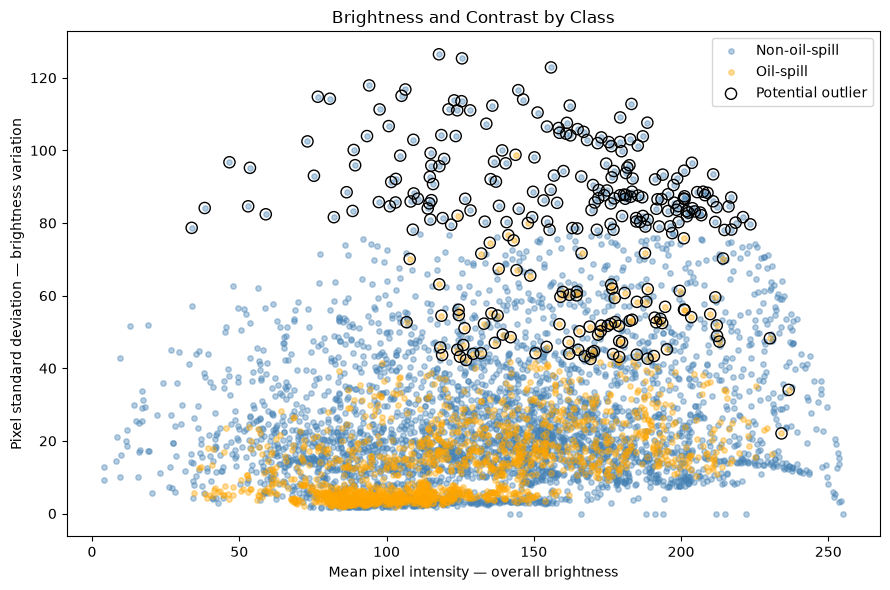

In [16]:
plt.figure(figsize=(9, 6))

for label, color in [
    ("Non-oil-spill", "steelblue"),
    ("Oil-spill", "orange")
]:
    group = image_stats[image_stats["class"] == label]

    plt.scatter(
        group["mean_intensity"],
        group["std_intensity"],
        color=color,
        alpha=0.4,
        s=15,
        label=label
    )

plt.scatter(
    outliers["mean_intensity"],
    outliers["std_intensity"],
    facecolors="none",
    edgecolors="black",
    s=65,
    label="Potential outlier"
)

plt.xlabel("Mean pixel intensity — overall brightness")
plt.ylabel("Pixel standard deviation — brightness variation")
plt.title("Brightness and Contrast by Class")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_folder / "brightness_contrast_outliers.png",
    dpi=150
)

plt.show()

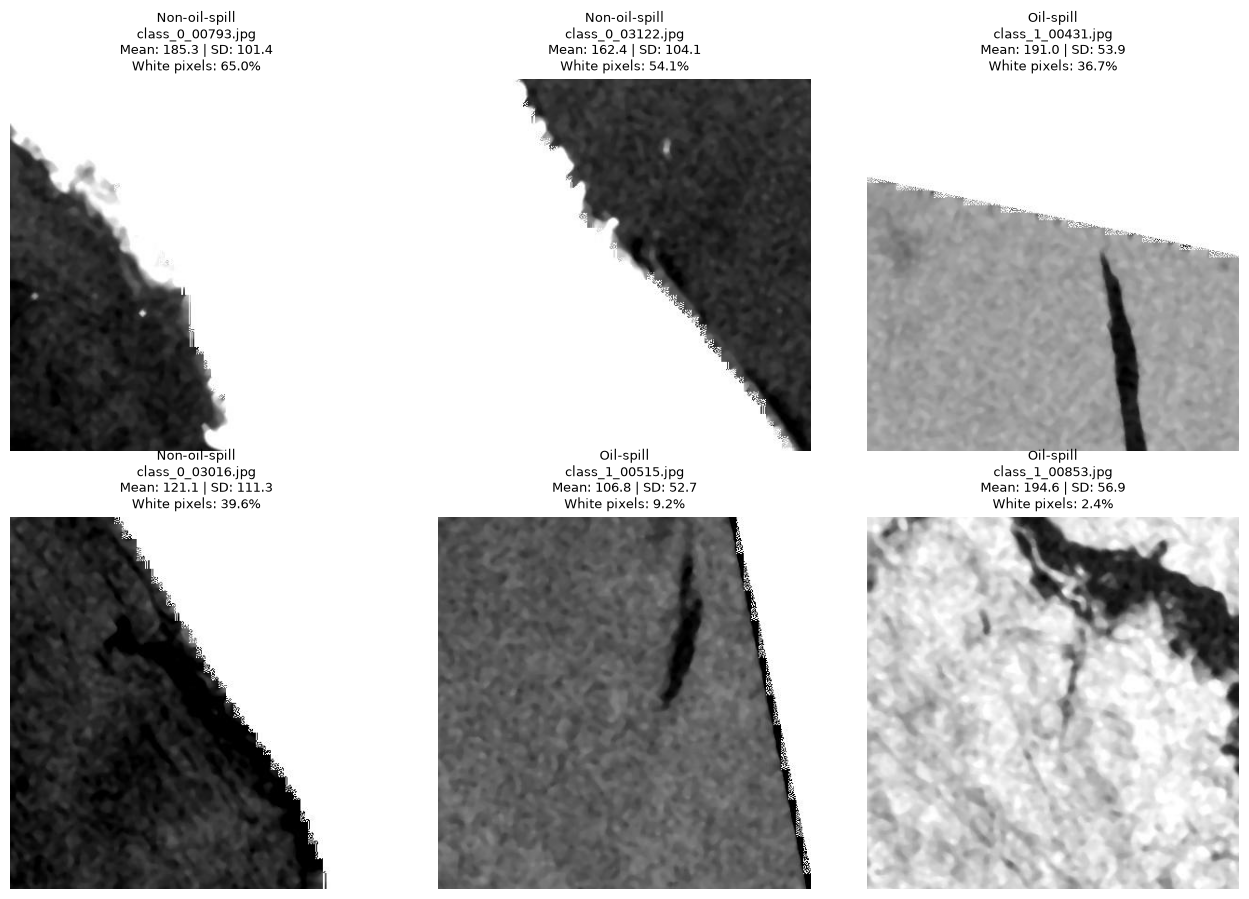

,filename,class,mean_intensity_outlier,std_intensity_outlier
792,class_0_00793.jpg,Non-oil-spill,False,True
3121,class_0_03122.jpg,Non-oil-spill,False,True
4125,class_1_00431.jpg,Oil-spill,False,True
3015,class_0_03016.jpg,Non-oil-spill,False,True
4209,class_1_00515.jpg,Oil-spill,False,True
4547,class_1_00853.jpg,Oil-spill,False,True


In [17]:
if outliers.empty:
    print("No images were flagged by the IQR rule.")
else:
    selected_outliers = outliers.sample(
        n=min(6, len(outliers)),
        random_state=42
    )

    fig, axes = plt.subplots(2, 3, figsize=(13, 9))

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, record) in zip(
        axes.flat, selected_outliers.iterrows()
    ):
        image = cv2.imread(
            record["path"], cv2.IMREAD_GRAYSCALE
        )

        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(
            f"{record['class']}\n"
            f"{record['filename']}\n"
            f"Mean: {record['mean_intensity']:.1f} | "
            f"SD: {record['std_intensity']:.1f}\n"
            f"White pixels: {record['white_pixel_percent']:.1f}%",
            fontsize=9
        )

    plt.tight_layout()
    plt.savefig(
        output_folder / "outlier_examples.png",
        dpi=150
    )
    plt.show()

    display(selected_outliers[
        ["filename", "class",
         "mean_intensity_outlier", "std_intensity_outlier"]
    ])

In [18]:
summary = image_stats.groupby("class").agg(
    images=("filename", "count"),
    average_brightness=("mean_intensity", "mean"),
    median_brightness=("mean_intensity", "median"),
    average_contrast=("std_intensity", "mean"),
    flagged_images=("potential_outlier", "sum")
)

summary["percentage"] = (
    summary["images"] / summary["images"].sum() * 100
)

summary["flagged_percentage"] = (
    summary["flagged_images"] / summary["images"] * 100
)

summary = summary.round(2)

display(summary)

print("Unreadable images:", len(unreadable))

print("\nImage sizes:")
display(
    image_stats.groupby(["class", "height", "width"])
    .size()
    .reset_index(name="number_of_images")
)

summary.to_csv(output_folder / "class_summary.csv")
class_counts.to_csv(
    output_folder / "class_distribution.csv", index=False
)

print("Results saved in:", output_folder.resolve())

,images,average_brightness,median_brightness,average_contrast,flagged_images,percentage,flagged_percentage
class,,,,,,,
Non-oil-spill,3695,137.71,138.18,28.09,182,66.72,4.93
Oil-spill,1843,122.12,113.99,14.46,93,33.28,5.05


Unreadable images: 0

Image sizes:


,class,height,width,number_of_images
0,Non-oil-spill,400,400,3695
1,Oil-spill,400,400,1843


Results saved in: C:\Users\svetl\OneDrive\Desktop\ieee\outputs


### Class Distribution — Findings

The downloaded class folders contain 5,538 images:

- Non-oil-spill: 3,695 images (66.72%).
- Oil-spill: 1,843 images (33.28%).

The dataset is imbalanced, with approximately two non-oil images
for every oil image. Therefore, image characteristics should be
compared separately for each class rather than relying only on
pooled results.

A classifier predicting only “non-oil-spill” would achieve 66.72%
accuracy on these images, showing why accuracy alone could be
misleading. No classifier was trained in this project.

The metadata describes 5,630 images, which is 92 more than the
labelled files found locally. The reason remains unconfirmed.
The separate sample folder contains 10 images and was excluded
because its class labels were not established.

## Conclusion

This EDA examined 5,538 readable grayscale images, each measuring
400 × 400 pixels. The dataset contains 3,695 non-oil-spill images
(66.72%) and 1,843 oil-spill images (33.28%), giving an approximately
2:1 class imbalance.

Oil-spill images had lower average brightness (122.12 versus
137.71) and lower average within-image pixel standard deviation
(14.46 versus 28.09). However, the class distributions overlap
substantially, so these statistics alone do not reliably
distinguish oil spills from non-oil images.

Visual inspection showed dark elongated and irregular features
in selected oil-spill images, alongside considerable variation
in background brightness and texture. These examples do not
establish a universal visual rule for either class.

Class-wise IQR screening flagged 182 non-oil images (4.93%)
and 93 oil images (5.05%). Inspection showed that strong
bright–dark boundaries, extensive white regions and dark
features can contribute to unusual intensity statistics.
Possible preprocessing or fill effects require confirmation.

All images were retained. The statistics describe stored JPEG
pixel values, not calibrated radar backscatter. The unexplained
difference between the metadata total of 5,630 and the 5,538
labelled images found locally remains a dataset limitation.

Overall, brightness and contrast reveal useful patterns, but
spatial features, image quality and acquisition context would
need further investigation before developing a detection model.
No model was trained or evaluated in this project.